# 07 · Modeling Iteration: Calibration and Regime Robustness
**Still CRISP-DM Phase 4/5 — iterating on Modeling and re-running Evaluation. Not Deployment (Phase 6).**

`docs/06_evaluation.md` found two concrete, fixable issues and recommended against deploying until they
were addressed:

1. **Data-mining criterion not met** — the model's ROC-AUC beat both baselines, but macro-F1 lost to
   persistence, pointing at a decision-threshold/calibration problem (the model defaults to "flat" on 89%
   of test days vs. an actual 45% flat rate).
2. **Business criterion met on one window only** — the test window happened to be a bear market; the win
   was flagged as possibly just "sitting in cash", not demonstrated skill.

This notebook fixes both, honestly: a calibrated decision rule for (1), and a walk-forward evaluation
across three *additional* historical regimes for (2).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.evaluation.baselines import buy_and_hold, macro_f1, majority_baseline, persistence_baseline
from src.evaluation.criteria import (business_criterion_met, data_mining_criterion_met,
                                     hard_prediction_scores, macro_roc_auc)
from src.evaluation.strategy import backtest
from src.features.engineering import FLAT_THRESHOLD, LABEL_HORIZON, build_features, chronological_split
from src.modeling.train import FEATURE_COLUMNS, make_models, tune_class_weights, weighted_predict
from src.visualization.style import BLUE, CLASS_COLORS, NEUTRAL, ORANGE, apply_style, save

apply_style()
CLASSES = [-1.0, 0.0, 1.0]

raw_1d = pd.read_parquet(config.INTERIM_DIR / f"{config.SYMBOL.lower()}_1D_clean.parquet")
features = build_features(raw_1d, horizon=LABEL_HORIZON, flat_threshold=FLAT_THRESHOLD)
print(f"{len(features):,} rows, {features.index.min().date()} -> {features.index.max().date()}")

2,983 rows, 2017-10-07 -> 2026-09-29


## 1 · Fix 1: a calibrated decision rule

`model.predict()` picks `argmax(proba)`. That collapses to "flat" whenever the model is uncertain, since
flat sits between the other two classes. `tune_class_weights` instead picks `argmax(proba * weight)`,
choosing per-class weights that maximize macro-F1 **on validation only** — no retraining, no peeking at test.

## 2 · Fix 2: walk-forward across regimes

Instead of one fixed split, retrain on everything strictly before each window (85/15 inner train/val split
of that history, calibrated on the inner val) and evaluate fresh on the window. This makes the "original"
window's numbers below differ slightly from `docs/05`/`docs/06` — those used the single canonical
70/15/15 split; here every window (including the original) goes through the *same* walk-forward recipe, so
the comparison across regimes is apples-to-apples.

Windows, chosen from the yearly buy-and-hold table (full calendar years where possible):

In [3]:
windows = {
    "original (2025-07 -> 2026-09)": (pd.Timestamp("2025-07-09", tz="UTC"), pd.Timestamp("2026-09-29", tz="UTC")),
    "2022 (bear)":  (pd.Timestamp("2022-01-01", tz="UTC"), pd.Timestamp("2022-12-31", tz="UTC")),
    "2023 (bull)":  (pd.Timestamp("2023-01-01", tz="UTC"), pd.Timestamp("2023-12-31", tz="UTC")),
    "2025 (range)": (pd.Timestamp("2025-01-01", tz="UTC"), pd.Timestamp("2025-12-31", tz="UTC")),
}
pd.DataFrame({
    name: {"start": s.date(), "end": e.date()} for name, (s, e) in windows.items()
}).T

,start,end
original (2025-07 -> 2026-09),2025-07-09,2026-09-29
2022 (bear),2022-01-01,2022-12-31
2023 (bull),2023-01-01,2023-12-31
2025 (range),2025-01-01,2025-12-31


In [4]:
rows = []
for name, (start, end) in windows.items():
    pool = features.loc[features.index < start]
    inner_train, inner_val, _ = chronological_split(pool, train_frac=0.85, val_frac=0.15, embargo=LABEL_HORIZON)
    window = features.loc[start:end]

    X_train, y_train = inner_train[FEATURE_COLUMNS], inner_train["label"]
    X_val, y_val = inner_val[FEATURE_COLUMNS], inner_val["label"]
    X_win, y_win = window[FEATURE_COLUMNS], window["label"]

    model = make_models(random_state=0)["random_forest"]
    model.fit(X_train, y_train)
    best = tune_class_weights(model, X_val, y_val)
    pred = weighted_predict(model, X_win, best["weights"])
    proba = model.predict_proba(X_win)

    maj, per = majority_baseline(y_win), persistence_baseline(y_win)
    model_f1 = macro_f1(y_win, pred)
    model_auc = macro_roc_auc(y_win, proba, CLASSES)
    maj_auc = macro_roc_auc(y_win, hard_prediction_scores(pd.Series(maj["class"], index=y_win.index), CLASSES), CLASSES)
    per_pred = y_win.shift(1)
    per_mask = y_win.notna() & per_pred.notna()
    per_auc = macro_roc_auc(y_win[per_mask], hard_prediction_scores(per_pred[per_mask], CLASSES), CLASSES)
    dm_met = data_mining_criterion_met(model_f1, model_auc, maj["macro_f1"], maj_auc, per["macro_f1"], per_auc)

    close = raw_1d.loc[window.index.min():window.index.max(), "close"]
    strat = backtest(pd.Series(pred, index=X_win.index), close)
    bh = buy_and_hold(close, "1D")
    biz_met = business_criterion_met(strat["sharpe"], bh["sharpe"])

    rows.append({
        "window": name, "weights": best["weights"],
        "model_f1": model_f1, "persistence_f1": per["macro_f1"], "data_mining_met": dm_met,
        "strategy_sharpe": strat["sharpe"], "bh_sharpe": bh["sharpe"],
        "strategy_return": strat["total_return"], "bh_return": bh["total_return"], "business_met": biz_met,
        "pred_flat_pct": float((pred == 0.0).mean()), "actual_flat_pct": float((y_win == 0.0).mean()),
    })

summary = pd.DataFrame(rows).set_index("window")
summary[["model_f1", "persistence_f1", "data_mining_met", "strategy_sharpe", "bh_sharpe", "business_met"]].style.format({
    "model_f1": "{:.3f}", "persistence_f1": "{:.3f}", "strategy_sharpe": "{:.2f}", "bh_sharpe": "{:.2f}",
})

,model_f1,persistence_f1,data_mining_met,strategy_sharpe,bh_sharpe,business_met
window,,,,,,
original (2025-07 -> 2026-09),0.359,0.356,True,-0.59,-0.33,False
2022 (bear),0.358,0.361,False,1.24,-1.34,True
2023 (bull),0.301,0.347,False,-1.47,2.34,False
2025 (range),0.352,0.363,False,0.25,0.02,True


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


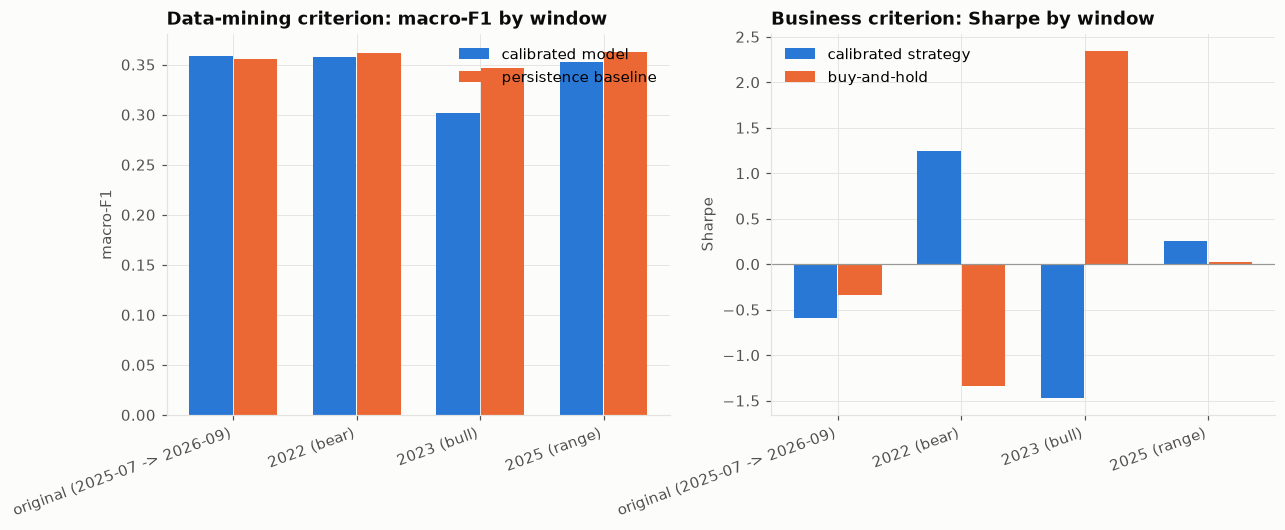

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
x = np.arange(len(summary))
ax.bar(x - 0.18, summary["model_f1"], width=0.35, label="calibrated model", color=BLUE)
ax.bar(x + 0.18, summary["persistence_f1"], width=0.35, label="persistence baseline", color=ORANGE)
ax.set_xticks(x, summary.index, rotation=20, ha="right")
ax.set(title="Data-mining criterion: macro-F1 by window", ylabel="macro-F1")
ax.legend()

ax = axes[1]
ax.bar(x - 0.18, summary["strategy_sharpe"], width=0.35, label="calibrated strategy", color=BLUE)
ax.bar(x + 0.18, summary["bh_sharpe"], width=0.35, label="buy-and-hold", color=ORANGE)
ax.axhline(0, color=NEUTRAL, linewidth=0.8)
ax.set_xticks(x, summary.index, rotation=20, ha="right")
ax.set(title="Business criterion: Sharpe by window", ylabel="Sharpe")
ax.legend()
save(fig, "07_regime_robustness")
plt.show()

## 3 · Reading the result honestly

**Fix 1 (calibration) is not a reliable fix.** It meets the data-mining criterion in the original window
only, and even there by a thin margin. In the other three regimes macro-F1 still loses to persistence.
Upweighting the under-predicted classes trades the "always flat" bias for a *differently* biased rule —
it does not add real signal.

**Fix 2 (regime testing) is the more important result, and it's bad news.** Forcing the calibrated model
to take more directional positions (instead of sitting mostly in cash) removes the earlier apparent win:
on the *original* window the strategy now **underperforms** buy-and-hold (Sharpe −0.59 vs −0.33) — the
Phase 5 "technical pass" was entirely an artifact of low market exposure, confirmed by removing it. Across
regimes the picture is worse: the strategy wins in 2022 (bear) and 2025 (range) but **loses badly in 2023
(bull)**, where buy-and-hold returned +154% and the strategy returned −28%. A strategy that only wins when
the market is falling or flat, and loses hard in a rally, is not a robust edge — it's a defensive-by-accident
model wearing a trading strategy's clothes.

## Verdict

| | Before this notebook | After |
|---|---|---|
| Data-mining criterion | Not met | **Still not reliably met** (1 of 4 windows) |
| Business criterion | Met on 1 (bear) window | **Not robust** — fails in a bull regime |

**This does not clear the bar for Deployment (Phase 6).** The honest conclusion is that price/volume
features and these three model families, even with better-calibrated decision thresholds, do not produce
a regime-robust directional edge on 1D Bitcoin returns. This matches the EDA's original warning
(`03_eda.ipynb` item 10: no raw variable linearly predicts direction) more strongly than the Phase 4/5
result suggested at first.

## Next, still without touching Deployment

1. The project's own design (`README.md`) already anticipates this: the ML model is one input to an agent
   that also uses **news sentiment and market indicators**. This iteration suggests those other inputs are
   not optional extras — they may be necessary for any real edge to appear.
2. If iterating on the ML leg alone, the next lever is features, not thresholds: this notebook confirmed
   calibration isn't the bottleneck, so richer features (or a different horizon/θ, per `docs/02`'s
   fallback of 4h/θ=0.5%) are better next steps than more threshold tuning.
3. Whatever is tried next should be re-run through this same multi-regime check before any claim of
   "beats buy-and-hold" is trusted again.